#### Normal Behavior Model (NBM) Residual Analysis & Operating Regime EDA

##### Motivation & Research Questions
When designing a predictive-maintenance system based on **Normal Behavior Modeling (NBM)**, the residual is our core detection signal:
$$r_t = y_{\text{actual}}(t) - \hat{y}_{\text{expected}}(t)$$

Most standard anomaly detection frameworks naively assume that residuals are **Gaussian (normally distributed)**, **homoscedastic (constant variance)**, and **independent and identically distributed (i.i.d.)**.

#### Key Questions Explored in this Notebook:
1. **Is the residual distribution Gaussian or Non-Gaussian?** (Testing skewness, kurtosis, and heavy tails).
2. **Does residual variance change with operating regimes?** (Testing heteroscedasticity across wind speed, power output, and ambient conditions).
3. **Do residuals have temporal autocorrelation?** (Examining thermal inertia memory in residuals).
4. **How does the residual distribution drift between normal operation and pre-fault degradation?**
5. **What do these empirical properties tell us about the best choice of Machine Learning & Deep Learning architectures?**


In [1]:
import os
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

# Styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Resolve data directory
current_dir = Path(os.getcwd())
if (current_dir / 'Care_To_Compare').exists():
    DATA_DIR = current_dir / 'Care_To_Compare'
elif (current_dir.parent / 'Care_To_Compare').exists():
    DATA_DIR = current_dir.parent / 'Care_To_Compare'
else:
    DATA_DIR = Path(r'c:/Users/veerk/Downloads/PRJ4/Care_To_Compare')

FARM_A_DIR = DATA_DIR / 'Wind Farm A'
print(f'Data directory set to: {FARM_A_DIR}')
assert FARM_A_DIR.exists(), f'Path not found: {FARM_A_DIR}'


Data directory set to: c:\Users\veerk\Downloads\PRJ4\Care_To_Compare\Wind Farm A


---
#### Fitting a Baseline Normal Behavior Model (NBM)
We build an NBM regressor on the historical healthy period (`train_test == 'train'`) for Wind Farm A Asset 0:
* **Target ($y$):** Generator Bearing DE Temperature (`sensor_13_avg`).
* **Operating Exogenous Predictors ($X$):** Active power (`power_30_avg`), wind speed (`wind_speed_3_avg`), ambient temperature (`sensor_0_avg`), generator RPM (`sensor_18_avg`), rotor RPM (`sensor_52_avg`), pitch angle (`sensor_5_avg`).
* **Filter:** Active generating mode (`status_type_id == 0`).


In [2]:
# Load Event 0 dataset (Generator bearing failure on Asset 0)
df_event0 = pd.read_csv(FARM_A_DIR / 'datasets' / '0.csv', sep=';')
df_event0['time_stamp'] = pd.to_datetime(df_event0['time_stamp'])

FEATURE_COLS = [
    'power_30_avg',      # Active power (kW)
    'wind_speed_3_avg',  # Wind speed (m/s)
    'sensor_0_avg',      # Ambient temperature (°C)
    'sensor_18_avg',     # Generator RPM
    'sensor_52_avg',     # Rotor RPM
    'sensor_5_avg'       # Pitch angle (°)
]
TARGET_COL = 'sensor_13_avg'  # Generator bearing Drive End temperature (°C)

# Isolate training split (normal baseline operation)
train_mask = (df_event0['train_test'] == 'train') & (df_event0['status_type_id'] == 0)
train_data = df_event0[train_mask].dropna(subset=FEATURE_COLS + [TARGET_COL]).copy()

X_train = train_data[FEATURE_COLS]
y_train = train_data[TARGET_COL]

print(f'Normal training samples: {len(X_train):,} timesteps (~{len(X_train)*10/60/24:.1f} operational days)')

# Fit a fast, non-linear Gradient Boosted Regressor as the baseline NBM
nbm_regressor = HistGradientBoostingRegressor(max_iter=60, random_state=42)
nbm_regressor.fit(X_train, y_train)

# Predict expected normal temperatures and compute residuals
y_train_pred = nbm_regressor.predict(X_train)
train_residuals = y_train - y_train_pred
train_data['residual'] = train_residuals

r2 = r2_score(y_train, y_train_pred)
mae = mean_absolute_error(y_train, y_train_pred)
rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

print(f'NBM Fit on Normal Train Baseline: R2 = {r2:.4f} | MAE = {mae:.2f}°C | RMSE = {rmse:.2f}°C')


Normal training samples: 47,252 timesteps (~328.1 operational days)
NBM Fit on Normal Train Baseline: R2 = 0.8615 | MAE = 4.04°C | RMSE = 5.38°C


---
#### Normality, Skewness & Kurtosis Tests (Train Residuals)
We test whether the baseline residuals follow a standard Gaussian distribution $\mathcal{N}(\mu, \sigma^2)$.


In [3]:
# Compute statistical higher moments
mean_res = np.mean(train_residuals)
std_res = np.std(train_residuals)
skew_res = stats.skew(train_residuals)
kurt_res = stats.kurtosis(train_residuals)  # Excess kurtosis (0 for normal)

# D'Agostino-Pearson omnibus test for normality
k2_stat, p_val = stats.normaltest(train_residuals)

print('=== Residual Higher-Order Statistics (Train Baseline) ===')
print(f'Mean:            {mean_res:.4f} °C')
print(f'Std Dev:         {std_res:.4f} °C')
print(f'Skewness:        {skew_res:.4f} (Gaussian = 0.0)')
print(f'Excess Kurtosis: {kurt_res:.4f} (Gaussian = 0.0)')
print(f"D'Agostino K^2:  {k2_stat:.2f} (p-value: {p_val:.2e})")

if p_val < 1e-5:
    print('=> CONCLUSION: Residuals are decisively NON-GAUSSIAN (Reject H0 with p < 1e-5).')
else:
    print('=> CONCLUSION: Residuals fail to reject Gaussianity.')


=== Residual Higher-Order Statistics (Train Baseline) ===
Mean:            -0.0181 °C
Std Dev:         5.3831 °C
Skewness:        0.1422 (Gaussian = 0.0)
Excess Kurtosis: 1.6633 (Gaussian = 0.0)
D'Agostino K^2:  1923.61 (p-value: 0.00e+00)
=> CONCLUSION: Residuals are decisively NON-GAUSSIAN (Reject H0 with p < 1e-5).


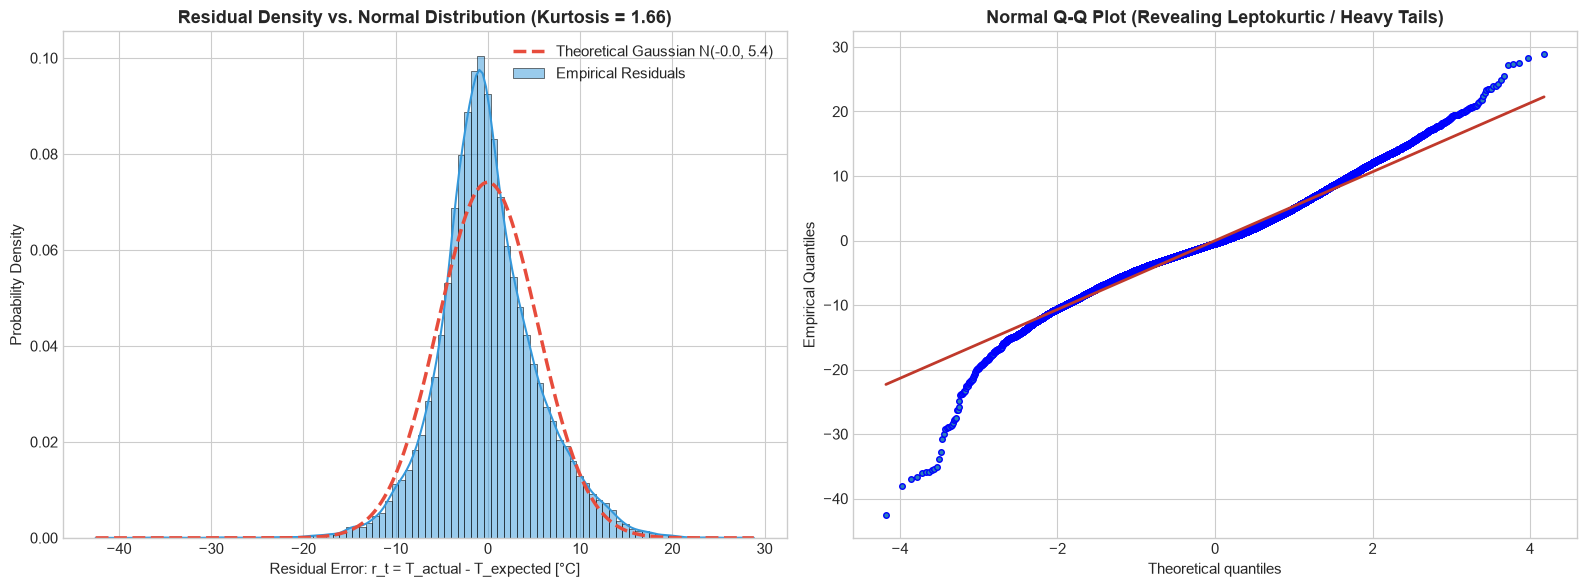

In [4]:
# Visualizing Non-Gaussianity: Histogram vs. Normal Fit & Q-Q Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Histogram & KDE vs Theoretical Normal
sns.histplot(train_residuals, bins=100, kde=True, stat='density', color='#3498db', ax=axes[0], label='Empirical Residuals')
x_grid = np.linspace(train_residuals.min(), train_residuals.max(), 300)
gaussian_pdf = stats.norm.pdf(x_grid, mean_res, std_res)
axes[0].plot(x_grid, gaussian_pdf, color='#e74c3c', lw=2.5, linestyle='--', label=f'Theoretical Gaussian N({mean_res:.1f}, {std_res:.1f})')
axes[0].set_title(f'Residual Density vs. Normal Distribution (Kurtosis = {kurt_res:.2f})', weight='bold')
axes[0].set_xlabel('Residual Error: r_t = T_actual - T_expected [°C]')
axes[0].set_ylabel('Probability Density')
axes[0].legend()

# Plot 2: Normal Quantile-Quantile (Q-Q) Plot
stats.probplot(train_residuals, dist='norm', plot=axes[1])
axes[1].get_lines()[0].set_markerfacecolor('#2980b9')
axes[1].get_lines()[0].set_markersize(4)
axes[1].get_lines()[1].set_color('#c0392b')
axes[1].get_lines()[1].set_linewidth(2)
axes[1].set_title('Normal Q-Q Plot (Revealing Leptokurtic / Heavy Tails)', weight='bold')
axes[1].set_ylabel('Empirical Quantiles')

plt.tight_layout()
plt.show()


---
#### Operating Regime Dependency & Heteroscedasticity
Does residual variance remain constant (homoscedastic), or does error variance expand during specific wind, power, or thermal operating regimes?


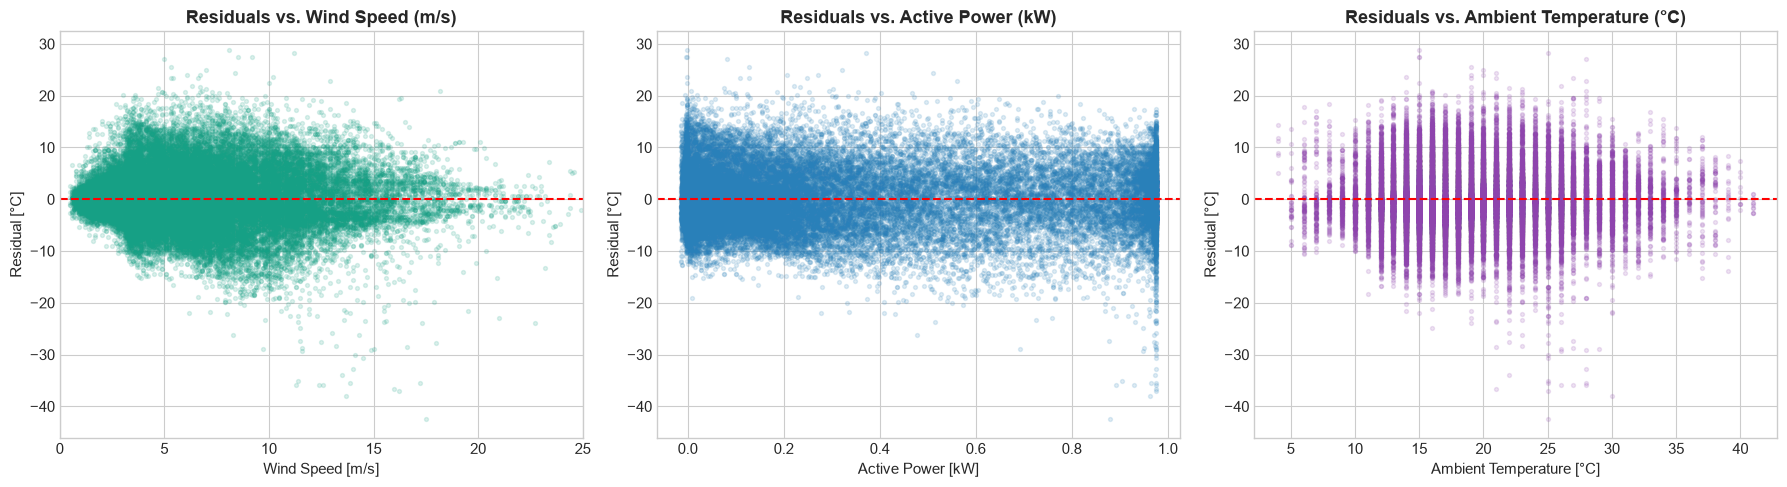

In [5]:
# Plot Residuals against Operating Regime Drivers
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Residuals vs Wind Speed
axes[0].scatter(train_data['wind_speed_3_avg'], train_data['residual'], alpha=0.15, s=8, color='#16a085')
axes[0].axhline(0, color='red', linestyle='--', lw=1.5)
axes[0].set_title('Residuals vs. Wind Speed (m/s)', weight='bold')
axes[0].set_xlabel('Wind Speed [m/s]')
axes[0].set_ylabel('Residual [°C]')
axes[0].set_xlim(0, 25)

# Residuals vs Active Power
axes[1].scatter(train_data['power_30_avg'], train_data['residual'], alpha=0.15, s=8, color='#2980b9')
axes[1].axhline(0, color='red', linestyle='--', lw=1.5)
axes[1].set_title('Residuals vs. Active Power (kW)', weight='bold')
axes[1].set_xlabel('Active Power [kW]')
axes[1].set_ylabel('Residual [°C]')

# Residuals vs Ambient Temperature
axes[2].scatter(train_data['sensor_0_avg'], train_data['residual'], alpha=0.15, s=8, color='#8e44ad')
axes[2].axhline(0, color='red', linestyle='--', lw=1.5)
axes[2].set_title('Residuals vs. Ambient Temperature (°C)', weight='bold')
axes[2].set_xlabel('Ambient Temperature [°C]')
axes[2].set_ylabel('Residual [°C]')

plt.tight_layout()
plt.show()


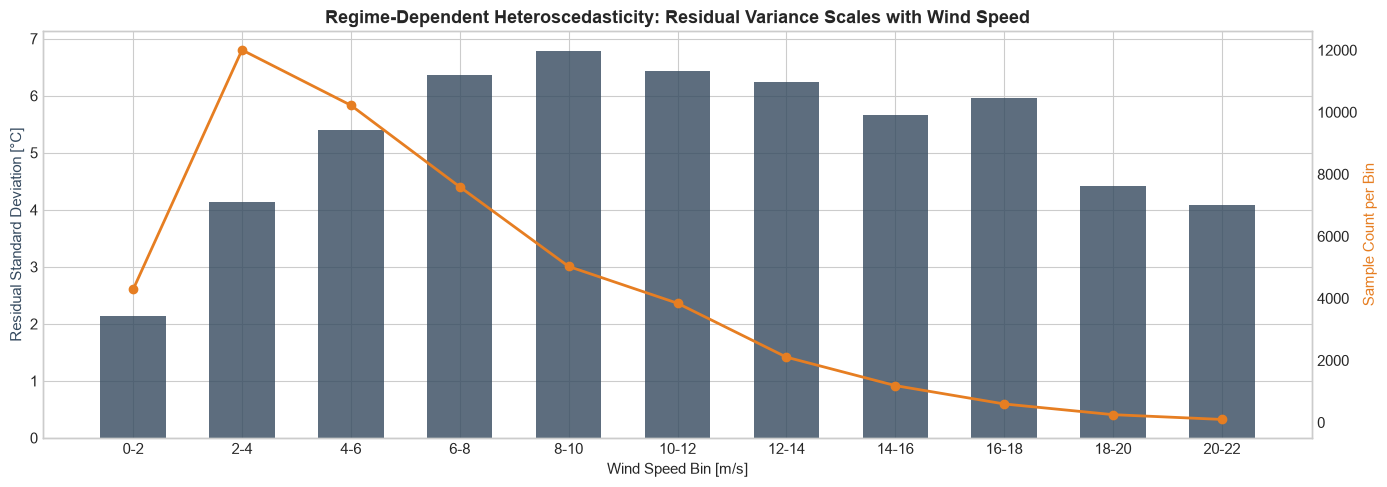

,Count,Mean Residual,Std Dev (Residual),90% Inter-Quantile Range
wind_bin,,,,
"(0, 2]",4285,-0.03,2.13,6.63
"(2, 4]",12005,-0.06,4.14,13.58
"(4, 6]",10222,-0.01,5.39,17.78
"(6, 8]",7593,-0.04,6.36,20.64
"(8, 10]",5027,0.05,6.79,22.44
"(10, 12]",3841,-0.00,6.44,20.61
"(12, 14]",2104,0.21,6.23,18.75
"(14, 16]",1187,-0.14,5.66,16.33
"(16, 18]",595,0.13,5.96,15.94


In [6]:
# Quantifying Heteroscedasticity: Residual Variance across Wind Speed Bins
train_data['wind_bin'] = pd.cut(train_data['wind_speed_3_avg'], bins=np.arange(0, 24, 2))
binned_stats = train_data.groupby('wind_bin', observed=True)['residual'].agg(['count', 'mean', 'std', lambda x: np.percentile(x, 95) - np.percentile(x, 5)])
binned_stats.columns = ['Count', 'Mean Residual', 'Std Dev (Residual)', '90% Inter-Quantile Range']

fig, ax1 = plt.subplots(figsize=(14, 5))

bin_labels = [f'{int(b.left)}-{int(b.right)}' for b in binned_stats.index]
x_pos = np.arange(len(bin_labels))

ax1.bar(x_pos, binned_stats['Std Dev (Residual)'], color='#34495e', alpha=0.8, width=0.6, label='Residual Std Dev (sigma_r)')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(bin_labels)
ax1.set_xlabel('Wind Speed Bin [m/s]')
ax1.set_ylabel('Residual Standard Deviation [°C]', color='#34495e')
ax1.set_title('Regime-Dependent Heteroscedasticity: Residual Variance Scales with Wind Speed', weight='bold')

ax2 = ax1.twinx()
ax2.plot(x_pos, binned_stats['Count'], color='#e67e22', marker='o', lw=2, label='Sample Count')
ax2.set_ylabel('Sample Count per Bin', color='#e67e22')
ax2.grid(False)

plt.tight_layout()
plt.show()

display(binned_stats.round(2))


---
#### Autocorrelation & Temporal Memory in Residuals
If residuals are purely random white noise, the autocorrelation for lags $k \ge 1$ should be $\approx 0$.
However, physical thermal inertia means heating and cooling deviations persist across several timesteps.


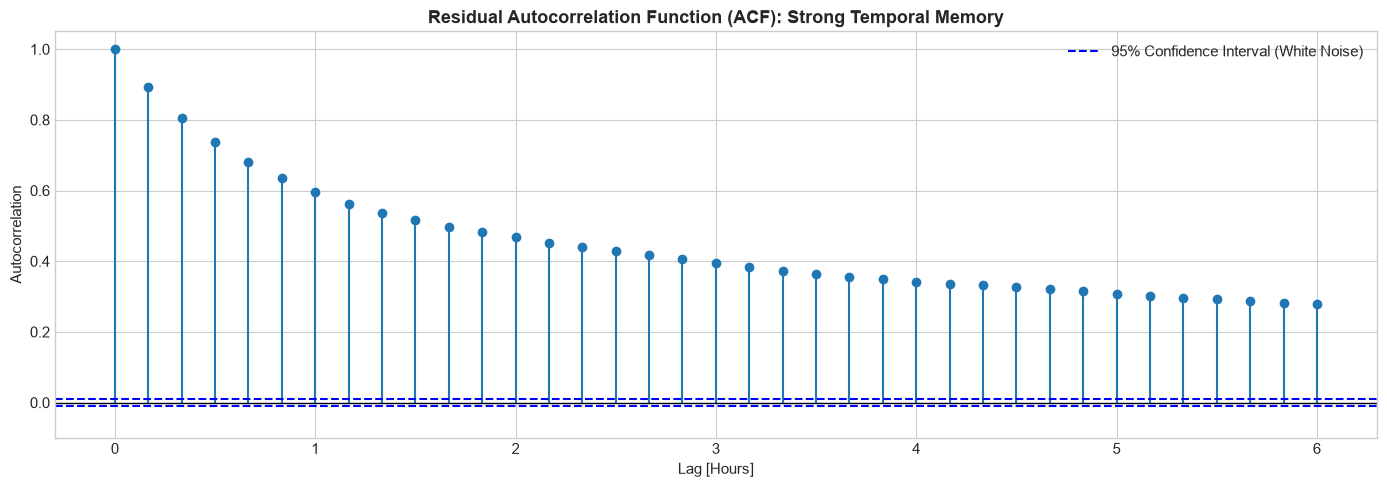

Lag 1 (10-min) Autocorrelation: 0.893
Lag 6 (1-hour) Autocorrelation: 0.595
Lag 18 (3-hour) Autocorrelation: 0.396


In [8]:
# Compute Autocorrelation Function (ACF) up to 36 lags (6 hours)
try:
    from statsmodels.tsa.stattools import acf
except ImportError:
    acf = lambda x, nlags: [x.autocorr(i) for i in range(nlags + 1)]
    
MAX_LAGS = 36  # 36 ten-minute steps = 6 hours
acf_values = [train_residuals.autocorr(lag) for lag in range(MAX_LAGS + 1)]
lags_hours = np.arange(MAX_LAGS + 1) * 10 / 60

plt.figure(figsize=(14, 5))
plt.stem(lags_hours, acf_values, basefmt=' ')
plt.axhline(0, color='black', lw=1)
plt.axhline(1.96 / np.sqrt(len(train_residuals)), color='blue', linestyle='--', label='95% Confidence Interval (White Noise)')
plt.axhline(-1.96 / np.sqrt(len(train_residuals)), color='blue', linestyle='--')
plt.title('Residual Autocorrelation Function (ACF): Strong Temporal Memory', weight='bold')
plt.xlabel('Lag [Hours]')
plt.ylabel('Autocorrelation')
plt.ylim(-0.1, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

print(f'Lag 1 (10-min) Autocorrelation: {acf_values[1]:.3f}')
print(f'Lag 6 (1-hour) Autocorrelation: {acf_values[6]:.3f}')
print(f'Lag 18 (3-hour) Autocorrelation: {acf_values[18]:.3f}')


---
#### Train vs. Test Residual Distribution Shift (Normal vs. Failure)
Now, we compare the residual distribution across three regimes:
1. **Baseline Train (Normal Operation)**
2. **Healthy Test Dataset (Event 24 `prediction` split)**
3. **Impending Failure Test Dataset (Event 0 `prediction` split, leading to breakdown)**


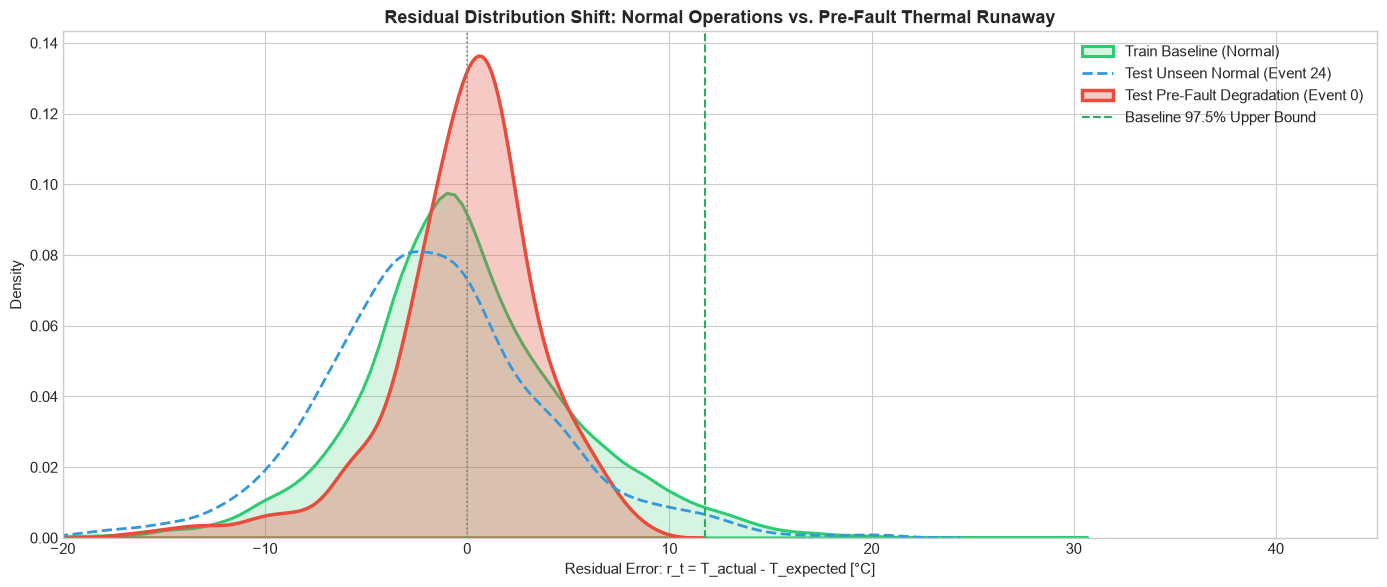

Kolmogorov-Smirnov Test (Normal vs. Pre-Fault): KS = 0.1309 (p-value: 7.47e-07)
Wasserstein Distance (Distribution Shift):       1.50 °C


In [9]:
# Load Normal Test Event 24
df_event24 = pd.read_csv(FARM_A_DIR / 'datasets' / '24.csv', sep=';')
df_event24['time_stamp'] = pd.to_datetime(df_event24['time_stamp'])

# Normal test prediction split
norm_test_mask = (df_event24['train_test'] == 'prediction') & (df_event24['status_type_id'] == 0)
test_norm_data = df_event24[norm_test_mask].dropna(subset=FEATURE_COLS + [TARGET_COL]).copy()
test_norm_pred = nbm_regressor.predict(test_norm_data[FEATURE_COLS])
res_test_norm = test_norm_data[TARGET_COL] - test_norm_pred

# Anomaly Test Event 0 (Pre-fault window up to event_start_id)
event_info_a = pd.read_csv(FARM_A_DIR / 'event_info.csv', sep=';')
start_id_0 = event_info_a[event_info_a['event_id'] == 0]['event_start_id'].iloc[0]

anom_test_mask = (df_event0['id'] >= start_id_0 - 432) & (df_event0['id'] < start_id_0) & (df_event0['status_type_id'] == 0)
test_anom_data = df_event0[anom_test_mask].dropna(subset=FEATURE_COLS + [TARGET_COL]).copy()
test_anom_pred = nbm_regressor.predict(test_anom_data[FEATURE_COLS])
res_test_anom = test_anom_data[TARGET_COL] - test_anom_pred

# Distribution shift comparison plot
plt.figure(figsize=(14, 6))
sns.kdeplot(train_residuals, color='#2ecc71', lw=2.2, label='Train Baseline (Normal)', fill=True, alpha=0.2)
sns.kdeplot(res_test_norm, color='#3498db', lw=2.0, linestyle='--', label='Test Unseen Normal (Event 24)')
sns.kdeplot(res_test_anom, color='#e74c3c', lw=2.5, label='Test Pre-Fault Degradation (Event 0)', fill=True, alpha=0.3)

plt.axvline(0, color='gray', linestyle=':', lw=1.2)
plt.axvline(train_residuals.quantile(0.975), color='#27ae60', linestyle='--', label='Baseline 97.5% Upper Bound')
plt.title('Residual Distribution Shift: Normal Operations vs. Pre-Fault Thermal Runaway', weight='bold')
plt.xlabel('Residual Error: r_t = T_actual - T_expected [°C]')
plt.ylabel('Density')
plt.xlim(-20, 45)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Statistical divergence tests
ks_stat, ks_pval = stats.ks_2samp(train_residuals, res_test_anom)
wasserstein = stats.wasserstein_distance(train_residuals, res_test_anom)
print(f'Kolmogorov-Smirnov Test (Normal vs. Pre-Fault): KS = {ks_stat:.4f} (p-value: {ks_pval:.2e})')
print(f'Wasserstein Distance (Distribution Shift):       {wasserstein:.2f} °C')


##### Summary for Implementation in `02_ML`:
1. **Backbone NBM**: Use **XGBoost Regressor** or **TCN** trained with **Huber Loss** to predict expected thermal channels.
2. **Thresholding**: Replace the naive scalar $3\sigma$ bound with a **Regime-Aware or Quantile Threshold**.
3. **Alarm Engine**: Apply **One-Sided CUSUM** or an **Autoregressive Moving Filter (EMA)** to leverage the high temporal autocorrelation and completely eliminate single-point noise.


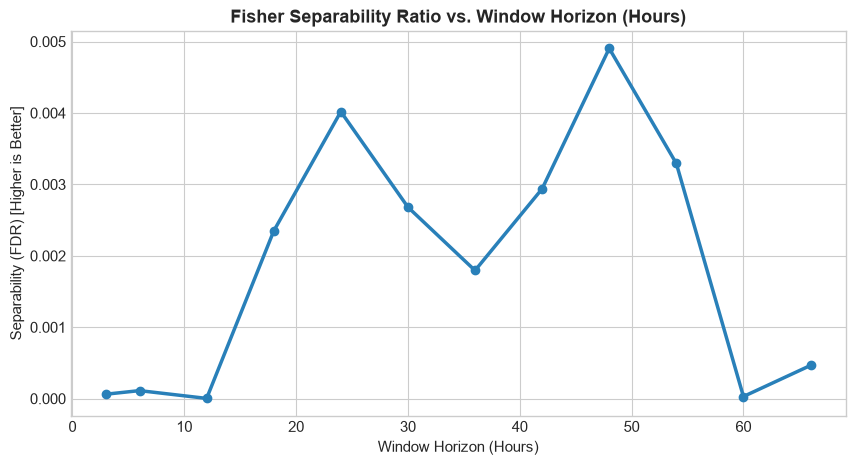

In [14]:
# Compare Window Separability across 3h, 6h, 12h, 24h, 48h
window_hours = [3, 6, 12, 18, 24, 30, 36, 42, 48, 54, 60, 66, 72, 78, 84, 90, 96, 108, 120]
fdr_scores = []

for h in window_hours:
    w = int(h * 6)  # 10-minute steps
    norm_w = [train_residuals[i:i+w].mean() for i in range(0, len(train_residuals) - w, 6)]
    anom_w = [res_test_anom[i:i+w].mean() for i in range(0, len(res_test_anom) - w, 6) if len(res_test_anom[i:i+w]) == w]
    
    m1, v1 = np.mean(norm_w), np.var(norm_w)
    m2, v2 = np.mean(anom_w), np.var(anom_w)
    fdr = ((m1 - m2)**2) / (v1 + v2 + 1e-8)
    fdr_scores.append(fdr)

plt.figure(figsize=(10, 5))
plt.plot(window_hours, fdr_scores, marker='o', lw=2.5, color='#2980b9')
plt.title('Fisher Separability Ratio vs. Window Horizon (Hours)', weight='bold')
plt.xlabel('Window Horizon (Hours)')
plt.ylabel('Separability (FDR) [Higher is Better]')
plt.grid(True)
plt.show()